# 02. TabPFN-2.5의 구조 변경 (2) — thinking 행과 회귀 MLP encoder

[01 노트북](01_layers_and_feature_groups.ipynb)은 TabPFN-2.5가 v2에서 바꾼 구조 네 가지 가운데 층 수(12 → 회귀 18, 분류 24)와 셀 3개 묶기를 봤습니다. 이 노트북은 나머지 둘, 학습되는 "thinking" 행 64개와 회귀 모델의 2층 MLP encoder를 작은 표로 따라가고, 마지막에 네 가지를 한 표로 정리합니다. 코드는 v2와 같은 `src/minipfn/models/cell_transformer.py`(`CellTransformer`)입니다. v1부터 3.5까지의 차이는 [노트북 로드맵의 버전 비교 표](../README.md#tabpfn-버전-비교)에 있습니다.

다루는 흐름:

1. thinking 행 64개
2. 회귀 encoder: Linear → 2층 MLP
3. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/04_tabpfn_v2_5/` 아래에 있으므로 저장소 루트는 두 단계 위입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn

from minipfn import set_seed
from minipfn.models import randomize_zero_weights
from minipfn.models.cell_transformer import CellTransformer, CellTransformerConfig

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.

1.2절과 1.3절에서는 [01 노트북](01_layers_and_feature_groups.ipynb) 3절의 과일 표를 씁니다. feature 5개, 학습 행 4개(사과 2, 배 2), 정답을 가린 테스트 행 2개입니다. 모델에 넣는 텐서까지 다시 만듭니다.

In [3]:
fruit = pd.DataFrame(
    {
        "무게(g)": [210, 190, 320, 290, 200, 310],
        "당도(brix)": [13.5, 14.0, 11.0, 11.5, 13.0, 12.0],
        "지름(cm)": [7.5, 7.2, 9.0, 8.6, 7.4, 8.8],
        "산도(pH)": [3.4, 3.5, 3.9, 3.8, 3.4, 3.9],
        "껍질(mm)": [0.6, 0.5, 1.0, 0.9, 0.6, 1.0],
    }
)
y = np.array([0, 0, 1, 1])  # 학습 행의 정답: 0 = 사과, 1 = 배
n_train = 4
roles = ["학습 1", "학습 2", "학습 3", "학습 4", "테스트 5", "테스트 6"]

features = fruit.to_numpy(dtype=float)
x = torch.tensor(features, dtype=torch.float32)[None]  # (데이터셋 1, 행 6, feature 5)
y_train = torch.tensor(y, dtype=torch.float32)[None]  # (데이터셋 1, 학습 행 4)
display(fruit.set_axis(roles))

,무게(g),당도(brix),지름(cm),산도(pH),껍질(mm)
학습 1,210,13.5,7.5,3.4,0.6
학습 2,190,14.0,7.2,3.5,0.5
학습 3,320,11.0,9.0,3.9,1.0
학습 4,290,11.5,8.6,3.8,0.9
테스트 5,200,13.0,7.4,3.4,0.6
테스트 6,310,12.0,8.8,3.9,1.0


## 1. thinking 행 64개

논문은 이렇게 적었습니다: "we add 64 additional "thinking" rows to the input dataset of TabPFN-2.5, which are learned during pretraining", 그리고 이 행이 "can also act as attention sinks to help the model ignore other rows". 정리하면 두 가지 역할입니다. 계산할 자리를 더 주는 것, 그리고 attention sink가 되는 것입니다. 둘째가 무슨 뜻인지 숫자로 먼저 봅니다.

### 1.1 attention sink — "아무것도 안 가져오기"

sample attention에서 테스트 행 하나가 학습 행 4개를 본다고 합시다. 계산을 줄여 학습 행마다 값(value)을 숫자 하나로 두고, 테스트 행의 query와 각 학습 행 key의 점수(score)를 직접 정합니다. 두 경우를 봅니다.

- **닮은 행이 있을 때**: 학습 1과의 점수만 4이고 나머지는 0
- **닮은 행이 없을 때**: 네 점수가 모두 0

softmax는 가중치의 합이 늘 1이 되도록 만듭니다. 그래서 닮은 행이 없어도 가중치를 어딘가에 나눠 줘야 하고, 결과는 학습 행 값의 평균이 됩니다. 여기에 점수 3, 값 0인 행(sink)을 하나 더하면 무엇이 달라지는지 비교합니다.

In [4]:
values = np.array([1.0, 2.0, 3.0, 4.0])  # 학습 1~4의 value (숫자 하나로 줄인 것)
SINK_SCORE, SINK_VALUE = 3.0, 0.0

cases = {
    "닮은 행이 있을 때": np.array([4.0, 0.0, 0.0, 0.0]),
    "닮은 행이 없을 때": np.array([0.0, 0.0, 0.0, 0.0]),
}
sink_rows = {}
for case, scores in cases.items():
    for with_sink in [False, True]:
        all_scores = np.concatenate([[SINK_SCORE], scores]) if with_sink else scores
        all_values = np.concatenate([[SINK_VALUE], values]) if with_sink else values
        weights = np.exp(all_scores) / np.exp(all_scores).sum()  # softmax
        if not with_sink:
            weights = np.concatenate([[np.nan], weights])  # sink 칸은 비워 둔다
        output = np.nansum(weights[1:] * values) + (weights[0] * SINK_VALUE if with_sink else 0.0)
        label = f"{case}, sink {'있음' if with_sink else '없음'}"
        sink_rows[label] = dict(
            zip(["sink", "학습 1", "학습 2", "학습 3", "학습 4"], weights, strict=True)
        ) | {"출력 (가중 평균)": output}

display(pd.DataFrame(sink_rows).T.round(2))

,sink,학습 1,학습 2,학습 3,학습 4,출력 (가중 평균)
"닮은 행이 있을 때, sink 없음",NaN,0.95,0.02,0.02,0.02,1.10
"닮은 행이 있을 때, sink 있음",0.26,0.70,0.01,0.01,0.01,0.82
"닮은 행이 없을 때, sink 없음",NaN,0.25,0.25,0.25,0.25,2.50
"닮은 행이 없을 때, sink 있음",0.83,0.04,0.04,0.04,0.04,0.42


sink가 없으면 닮은 행이 없을 때도 가중치가 0.25씩 퍼져 출력이 평균값 2.5가 됩니다. 테스트 행과 상관없는 학습 행들이 섞여 들어온 것입니다. sink가 있으면 가중치 대부분(0.83)이 sink로 가고, sink의 값이 0이라 출력이 0.42로 작아집니다. attention이 잔차에 더하는 것이 거의 없으니, 이 층에서 테스트 행은 "다른 행을 무시"하고 자기 토큰을 거의 그대로 갖고 갑니다. 닮은 행이 있을 때는 sink가 있어도 가중치 대부분(0.70)이 여전히 학습 1로 갑니다.

thinking 행이 없어도 모델은 학습 행 가운데 하나를 sink처럼 쓸 수 있습니다. 그러려면 그 행에 대한 점수를 다른 행보다 아주 크게 키워야 합니다. 이 저장소에서 v2 회귀를 논문 규모로 학습했을 때 실제로 sample attention이 행 하나에 몰렸고, attention logit의 상한이 수만~수십만으로 커진 뒤 학습이 불안정해졌습니다. 그래서 v2 회귀에는 QK-clip(`TrainConfig.qk_clip`)으로 logit 상한을 뒀습니다. thinking 행은 sink로 쓸 전용 자리를 따로 마련해 주는 셈입니다. 2.5 회귀 설정도 v2 회귀처럼 QK-clip 250을 그대로 씁니다. 2.5 학습에서 thinking 행이 실제로 sink가 되는지는 학습한 뒤 attention을 보며 확인합니다.

### 1.2 thinking 행을 어디에 어떻게 붙이나 (여기서 정한 것)

논문은 행 수와 "pretraining 때 학습된다"는 것만 적었고, 행을 어떻게 만들고 어디에 두는지는 적지 않았습니다. 이 저장소는 다음처럼 정했습니다.

- thinking 행 하나는 학습되는 벡터 하나($E$차원)이고, 그 행의 모든 열(feature 묶음과 y)에 같은 벡터를 씁니다. 열 이름표(column embedding)는 더하지 않습니다.
- 표의 맨 앞, 학습 행보다 앞에 둡니다. sample attention에서 학습 행처럼 key·value가 되어, 학습 행과 테스트 행 모두 thinking 행을 봅니다.
- thinking 행 자신도 query가 되어 층마다 갱신됩니다. 출력은 테스트 행에서만 읽으므로 thinking 행의 출력은 버립니다.
- 처음 값은 $0.02 \times$ 표준정규 난수입니다.

thinking 행 2개, 학습 행 4개, 테스트 행 2개로 sample attention이 누구를 보는지 그려 봅니다. 행은 attend하는 쪽, 열은 attend받는 쪽이고 1이면 attend합니다.

In [5]:
n_thinking = 2
names = [f"thinking {i + 1}" for i in range(n_thinking)] + roles
n_context = n_thinking + n_train  # key·value가 되는 행: thinking + 학습
allowed = (np.arange(len(names)) < n_context)[None].repeat(len(names), axis=0)
display(pd.DataFrame(allowed.astype(int), index=names, columns=names))

,thinking 1,thinking 2,학습 1,학습 2,학습 3,학습 4,테스트 5,테스트 6
thinking 1,1,1,1,1,1,1,0,0
thinking 2,1,1,1,1,1,1,0,0
학습 1,1,1,1,1,1,1,0,0
학습 2,1,1,1,1,1,1,0,0
학습 3,1,1,1,1,1,1,0,0
학습 4,1,1,1,1,1,1,0,0
테스트 5,1,1,1,1,1,1,0,0
테스트 6,1,1,1,1,1,1,0,0


v2의 규칙("모든 행이 학습 행만 본다")에서 key·value가 되는 행이 thinking 행까지로 늘어난 것뿐입니다. 그래서 mask가 여전히 필요 없고, 코드에서는 key·value로 쓰는 앞쪽 행 수 `n_context`를 `n_train + n_thinking_rows`로 늘리기만 합니다.

### 1.3 실제 모델에서 따라가기

thinking 행 4개짜리 작은 `CellTransformer`에 과일 표를 넣고, 첫 층에 들어가는 텐서와 나오는 텐서를 hook으로 꺼냅니다.

먼저 손볼 것이 하나 있습니다. 실제 모델은 attention의 출력 투영과 MLP의 마지막 Linear를 0으로 시작합니다. 학습 초기에 층이 잔차에 아무것도 더하지 않게 하려는 것입니다. 그대로 두면 학습 전 모델의 층은 아무 일도 하지 않으므로, 이 절과 다음 절에서는 확인용으로 0인 가중치를 무작위로 채웁니다.

In [6]:
torch.manual_seed(0)
config = CellTransformerConfig(
    emsize=16, nlayers=2, nhead=2, features_per_group=3, n_thinking_rows=4, n_out=2
)
thinker = randomize_zero_weights(CellTransformer(config)).eval()

captured = {}
hook = thinker.layers[0].register_forward_hook(
    lambda module, inputs, output: captured.update(h_in=inputs[0], h_out=output)
)
with torch.no_grad():
    logits = thinker(x, y_train)
hook.remove()

print("학습되는 thinking 행:", tuple(thinker.thinking_rows.shape), " (thinking 행, E)")
print("입력 x:              ", tuple(x.shape), " (데이터셋, 행, feature)")
print(
    "첫 층에 들어가는 h:  ",
    tuple(captured["h_in"].shape),
    " (데이터셋, thinking 4 + 행 6, 묶음 2 + y 1, E)",
)
print("출력 logit:          ", tuple(logits.shape), " (데이터셋, 테스트 행, 출력)")

학습되는 thinking 행: (4, 16)  (thinking 행, E)
입력 x:               (1, 6, 5)  (데이터셋, 행, feature)
첫 층에 들어가는 h:   (1, 10, 3, 16)  (데이터셋, thinking 4 + 행 6, 묶음 2 + y 1, E)
출력 logit:           (1, 2, 2)  (데이터셋, 테스트 행, 출력)


행 축이 6에서 10으로 늘었고, 출력은 여전히 테스트 행 2개에 대해서만 나옵니다. 첫 층에 들어갈 때 thinking 행은 열마다 같은 벡터입니다. 첫 층을 지난 뒤에는 열마다 다른 학습 행을 읽었으므로 열마다 달라집니다. 열 사이의 표준편차로 확인합니다.

In [7]:
thinking_in = captured["h_in"][0, :4]  # (thinking 4, 열 3, E)
thinking_out = captured["h_out"][0, :4]
display(
    pd.DataFrame(
        {
            "첫 층 전": thinking_in.std(dim=1).mean(dim=-1).numpy(),
            "첫 층 뒤": thinking_out.std(dim=1).mean(dim=-1).numpy(),
        },
        index=[f"thinking {i + 1}" for i in range(4)],
    )
    .rename_axis("열 사이 표준편차")
    .round(3)
)

,첫 층 전,첫 층 뒤
열 사이 표준편차,,
thinking 1,0.0,0.168
thinking 2,0.0,0.134
thinking 3,0.0,0.141
thinking 4,0.0,0.184


### 1.4 구조가 보장하는 성질은 그대로인가

[03_tabpfn_v2/02](../03_tabpfn_v2/02_attention_properties_and_cost.ipynb) 1절에서 본 성질 가운데 두 가지, 학습 행 순서를 바꿔도 예측이 같다는 것과 테스트 행 하나의 예측이 다른 테스트 행과 무관하다는 것을 thinking 행이 있는 모델로 다시 확인합니다. thinking 행은 늘 맨 앞 같은 자리에 있고, 테스트 행은 thinking 행과 학습 행만 보므로 둘 다 성립해야 합니다. 비교용으로 thinking 행의 값을 바꾸면 예측이 달라지는지도 봅니다. 1.3처럼 0인 가중치를 무작위로 채운 모델입니다.

In [8]:
torch.manual_seed(0)
config = CellTransformerConfig(
    emsize=16, nlayers=2, nhead=2, features_per_group=3, n_thinking_rows=4, n_out=3
)
checker = randomize_zero_weights(CellTransformer(config)).eval()

torch.manual_seed(1)
x_tr, y_tr = torch.randn(1, 20, 5), torch.randint(0, 3, (1, 20)).float()
x_te = torch.randn(1, 6, 5)


def predict(model, x_train, y_train, x_test):
    with torch.no_grad():
        return model(torch.cat([x_train, x_test], dim=1), y_train)


def max_diff(a, b):
    return f"{(a - b).abs().max().item():.1e}"


base = predict(checker, x_tr, y_tr, x_te)
perm = torch.randperm(20)
one_by_one = torch.cat([predict(checker, x_tr, y_tr, x_te[:, j : j + 1]) for j in range(6)], dim=1)

original = checker.thinking_rows.detach().clone()
with torch.no_grad():
    checker.thinking_rows.add_(0.5 * torch.randn_like(original))  # thinking 행 값만 바꾼다
changed = predict(checker, x_tr, y_tr, x_te)
with torch.no_grad():
    checker.thinking_rows.copy_(original)

display(
    pd.DataFrame(
        {
            "바꾼 것": ["학습 행 순서", "테스트 행을 하나씩 따로 넣기", "비교: thinking 행의 값"],
            "logit 최대 차이": [
                max_diff(base, predict(checker, x_tr[:, perm], y_tr[:, perm], x_te)),
                max_diff(base, one_by_one),
                max_diff(base, changed),
            ],
        }
    )
)

,바꾼 것,logit 최대 차이
0,학습 행 순서,1.3e-07
1,테스트 행을 하나씩 따로 넣기,1.3e-07
2,비교: thinking 행의 값,2.7e-02


앞의 둘은 float 반올림 오차 수준이고, thinking 행의 값을 바꾸면 예측이 달라집니다. thinking 행은 모든 데이터셋에 같은 값으로 붙는 학습된 파라미터이므로, 데이터셋에 따라 바뀌는 것은 thinking 행이 층을 지나며 읽어 들인 내용뿐입니다.

## 2. 회귀 encoder: Linear → 2층 MLP

논문은 "For our regression models, we found a small improvement by replacing the linear encoder used in TabPFNv2 by a 2-layer MLP"라고 적었습니다. 분류 모델은 linear encoder 그대로입니다. 어느 encoder인지는 적혀 있지 않은데, 이 저장소는 셀 묶음을 토큰으로 바꾸는 feature encoder(`feature_embedder`)로 봤습니다. y 셀의 encoder(`target_embedder`)는 linear 그대로이고, MLP는 Linear(2g → E) → GELU → Linear(E → E)입니다.

차이를 보려고 셀 묶음 하나의 첫 칸 값만 $-3$에서 $3$까지 바꾸고 나머지 칸과 결측 표시는 0으로 둔 채, 두 encoder가 만드는 토큰의 앞 세 차원을 그립니다. 학습하지 않은 무작위 가중치입니다.

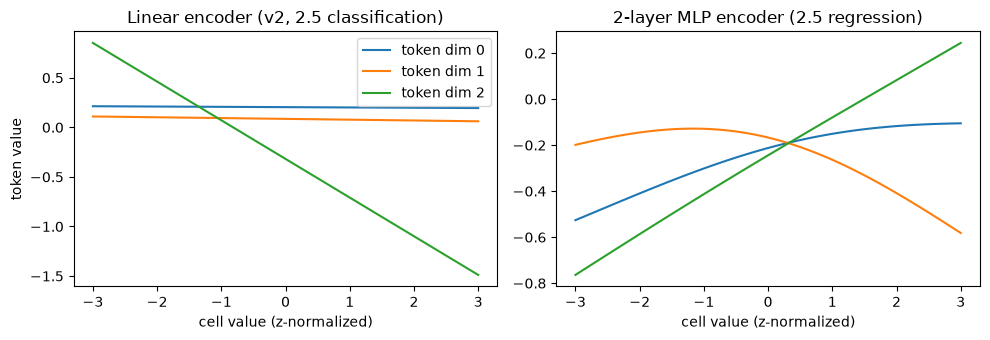

파라미터 수 (E = 192, g = 3): linear 1,344, MLP 38,400


In [9]:
g, E_small = 3, 16
torch.manual_seed(0)
linear_encoder = nn.Linear(2 * g, E_small)  # v2, 2.5 분류
mlp_encoder = nn.Sequential(
    nn.Linear(2 * g, E_small), nn.GELU(), nn.Linear(E_small, E_small)
)  # 2.5 회귀

sweep = torch.linspace(-3, 3, 121)
encoder_inputs = torch.zeros(len(sweep), 2 * g)
encoder_inputs[:, 0] = sweep  # 첫 칸 값만 바꾼다. 나머지 칸과 결측 표시 g개는 0
with torch.no_grad():
    outputs = {
        "Linear encoder (v2, 2.5 classification)": linear_encoder(encoder_inputs),
        "2-layer MLP encoder (2.5 regression)": mlp_encoder(encoder_inputs),
    }

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True)
for ax, (title, tokens) in zip(axes, outputs.items(), strict=True):
    for d in range(3):
        ax.plot(sweep, tokens[:, d], label=f"token dim {d}")
    ax.set_title(title)
    ax.set_xlabel("cell value (z-normalized)")
axes[0].set_ylabel("token value")
axes[0].legend()
plt.tight_layout()
plt.show()

linear_params = 2 * g * 192 + 192
mlp_params = linear_params + 192 * 192 + 192
print(f"파라미터 수 (E = 192, g = 3): linear {linear_params:,}, MLP {mlp_params:,}")

linear encoder의 토큰은 셀 값에 대해 직선입니다. 셀 값이 바뀌면 토큰은 정해진 한 방향으로만 움직이고, 값에 따라 꺾이는 표현은 그 뒤의 층들이 만들어야 합니다. MLP encoder는 토큰을 만들 때부터 값에 따라 꺾을 수 있습니다. 논문은 회귀에서 "작은 개선"이 있었다고만 적었고 이유는 설명하지 않았습니다. 파라미터는 192 × 192만큼 늘어 3만 8천 개 남짓이 되는데, 모델 전체(1,467만 개)에 비하면 작습니다.

## 3. 정리

| 바뀐 것 | v2 | 2.5 | 논문이 적은 것 | 여기서 정한 것 |
|---|---|---|---|---|
| 층 수 | 12 | 회귀 18, 분류 24 | 층 수 | — |
| 셀 묶음 크기 | 2 | 3 | 묶음 크기 | — |
| thinking 행 | 없음 | 64개 | 행 수, pretraining 때 학습, attention sink 역할 | 행마다 벡터 하나를 모든 열에 씀, 학습 행 앞에 둬 key·value로 씀, 처음 값 0.02 × 난수 |
| 회귀 encoder | Linear | 2층 MLP | Linear를 2층 MLP로 | feature 셀 묶음 encoder에 적용, hidden = E, GELU |
| 임베딩 크기, head 수 | 192, 6 | (적혀 있지 않음) | — | v2 그대로 192, 6 |

이 설정을 학습 설정에 입히는 것은 `with_architecture(paper(task), "v2.5")` 한 줄이고, 기본값은 v2 그대로라 v2 가중치도 같은 클래스로 읽습니다. 파라미터 수는 분류 723만 → 1,434만, 회귀 1,108만 → 1,467만입니다.

2.5 다음의 TabPFN-3은 이 2방향 attention 뼈대를 버리고 열 → 행 → 행 ICL 구조로 바꿉니다. 그 차이는 [노트북 로드맵의 버전 비교 표](../README.md#tabpfn-버전-비교)와 [05_tabpfn_v3/01 TabPFN-3 한눈에 보기와 셀 encoder](../05_tabpfn_v3/01_overview_and_cell_encoder.ipynb)에서 봅니다.

다음 노트북 [03 긴 표 학습](03_long_tables.ipynb)부터는 모델 밖에서 바뀐 것을 봅니다. 03은 학습 표의 크기이고, [04 추론 전처리](04_inference_preprocessing.ipynb)는 추론 때 앙상블 멤버의 전처리입니다.